<a href="https://colab.research.google.com/github/themintlab/ExecutableEngineering/blob/main/chapters/finite_element_method/elements.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Elements

&nbsp;[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/themintlab/ExecutableEngineering/blob/main/chapters/finite_element_method/elements.ipynb)

Shape functions are generally chosen to approximate the (unknown) function *on each element* in terms of the weights discussed above, which are generally called the *degrees of freedom* (DOFs).

The choice of *element type* determines:

* the function which approximates the solution on the element.
* the *nodes* - the points within the element at which the degrees of freedom are specified.
* the meaning of the DOFs, which might be:
  * function value
  * gradient
  * divergence of a vector field
* the continuity of the approximate solution between elements.
* integration scheme (typically in terms of the Gauss Points).

One might consider placing DOFs at the Gauss Points to expedite integration, but this is not common. It is more important for the shape functions to reflect the behaviour of the solution (e.g., continuity, conservation of divergence, high order variations).

In [1]:
import numpy as np
from scipy.special import jv
import plotly.graph_objects as go
import ipywidgets as widgets
from ipywidgets import interact

## Lagrange elements

A general purpose basis is our good old Lagrange interpolation functions! These functions have nodes at the verticies of the mesh (at least), at which the value of the function is specified. Higher order elements (i.e. higher order polynomials) include additional nodes *inside* the element.

LaGrange shape functions are 1 at the associated node and 0 at *every* other node.    

$$\phi_i(x_j) = \delta_{ij}$$

The first three orders (in 1D) are:


| **Order** | **Node** ................   | **Basis Function**..................................................                                   |
|-----------|-----------------------|------------------------------------------------------|
| 0    | $x_0 = 0$             | $\phi_0(x) = 1$                                      |
| 1     | $x_0 = 0$             | $\phi_0(x) = 1 - x$                                  |
|           | $x_1 = 1$             | $\phi_1(x) = x$                                      |
| 2    | $x_0 = 0$             | $\phi_0(x) = 2(1 - x)(0.5 - x)$                      |
|           | $x_1 = 0.5$           | $\phi_1(x) = 4x(1 - x)$                              |
|           | $x_2 = 1$             | $\phi_2(x) = 2x(x - 0.5)$                            |
| 3     | $x_0 = 0$             | $\phi_0(x) = -9/2 (x - 1/3)(x - 2/3)(x - 1)$         |
|           | $x_1 = 1/3$           | $\phi_1(x) = 27/2 x(x - 2/3)(x - 1)$                 |
|           | $x_2 = 2/3$           | $\phi_2(x) = -27/2 x(x - 1/3)(x - 1)$                |
|           | $x_3 = 1$             | $\phi_3(x) = 9/2 x(x - 1/3)(x - 2/3)$                |

In [4]:
import matplotlib.pyplot as plt

def lagrange_basis(order, x, node):
    nodes = np.array([0.5]) if order == 0 else np.linspace(0, 1, order + 1)
    basis = np.ones_like(x)
    for j in range(order + 1):
        if j != node:
            basis *= (x - nodes[j]) / (nodes[node] - nodes[j])
    return basis

def plot_lagrange_basis(order):
    x = np.linspace(0, 1, 500)
    nodes = np.array([0.5]) if order == 0 else np.linspace(0, 1, order + 1)

    plt.figure(figsize=(10, 5))
    for node in range(order + 1):
        y = lagrange_basis(order, x, node)
        # Plot the basis function line
        line, = plt.plot(x, y, label=f"Node {node}")
        # Plot the node marker at y=1
        plt.plot([nodes[node]], [1], marker='o', markersize=8, color=line.get_color())

    plt.title(f"Lagrange Basis Functions of Order {order}")
    plt.xlabel("x")
    plt.ylabel("Basis Function Value")
    plt.ylim(-0.4, 1.2)
    plt.grid(True, linestyle='--', alpha=0.6)
    if order > 0:
        plt.legend()
    plt.show()

interact(plot_lagrange_basis, order=widgets.IntSlider(min=0, max=3, step=1, value=0))


interactive(children=(IntSlider(value=0, description='order', max=3), Output()), _dom_classes=('widget-interac…

## Continuity

Since the Lagrange shape functions are defined *at least* on the mesh vertices, those DOFs may be shared between adjacent elements. This enforces continuity in the solution at the nodes (at least the vertices) and, if both adjacent elements are of the same type/order, along $\partial \Omega$ too.

The flux / first derivative however is not generally continuous. However, the weak form does not require this continuity to approximate a second order (in space) PDE!

Take another look at the Lagrange element order 0 above. It doesn't have DOFs at the end points and so this is actually a *discontinuous Lagrange element*.

## Example: Tent functions

An illustrative example is the 1D linear Lagrange elements, which are lines inside the element (interval). Continuity between elements implies sharing the vertex values and therefore we see *tent / triangle* functions.

Note that since the shape functions are $1$ only at the mesh vertices, calculating the weights is as easy as evaluating the function at those points!

In [3]:
rng = np.random.default_rng(42)
mesh = np.concatenate(([0.0], np.sort(rng.uniform(0.2, 4.8, 8)), [5.0]))

def tent_function(x, xi, x_prev, x_next):
    if x_prev < xi and x_prev <= x <= xi:
        return (x - x_prev) / (xi - x_prev)
    elif xi < x_next and xi <= x <= x_next:
        return (x_next - x) / (x_next - xi)
    return 0.0

coefficients = jv(0, mesh)
x_vals = np.linspace(0, 5, 500)
approximation = np.zeros_like(x_vals)

fig = go.Figure()
for i, xi in enumerate(mesh):
    x_prev = mesh[i - 1] if i > 0 else xi
    x_next = mesh[i + 1] if i < len(mesh) - 1 else xi
    tent = np.array([tent_function(x, xi, x_prev, x_next) for x in x_vals])
    approximation += coefficients[i] * tent
    fig.add_trace(go.Scatter(x=x_vals, y=coefficients[i] * tent, name=f"Scaled Tent {i+1}", opacity=0.45, line=dict(width=1.5)))

fig.add_trace(go.Scatter(x=x_vals, y=jv(0, x_vals), name="Original Bessel Function", line=dict(color="blue", width=2.5)))
fig.add_trace(go.Scatter(x=x_vals, y=approximation, name="Approximation", line=dict(color="red", width=2.5, dash="dash")))
fig.add_trace(go.Scatter(x=mesh, y=coefficients, mode="markers", name="Mesh Points", marker=dict(color="black", size=8)))
fig.update_layout(
    title="Bessel Function Approximation Using Tent Functions",
    xaxis_title="x",
    yaxis_title="Value",
    template="plotly_white",
)
fig.show()

## 2D and 3D, and other shapes

Extension to 2D and 3D is fairly straight-forward, beginning with the vertices and then refining by subdivision.

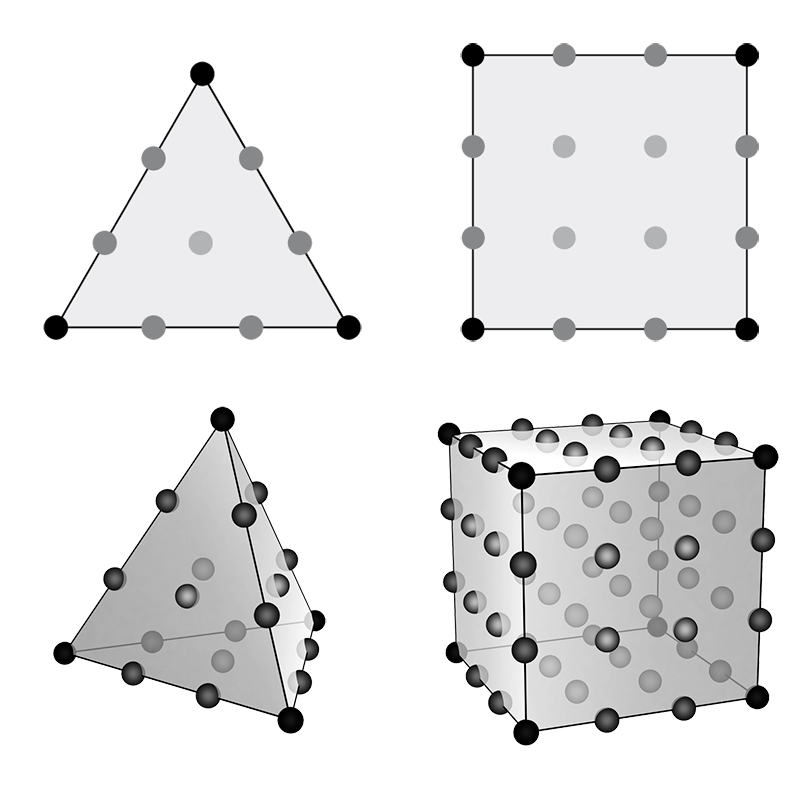

## Advanced elements

The field of Finite Elements is very rich, with elements designed specifically for certain types of physics, e.g.:

* Curl of a vector field
* Divergence of a vector field
* Discontinuous elements
* Spectral Elements (very high order based on orthogonal shape functions).

A first step may be the [Periodic Table of Finite Elements](https://www-users.cse.umn.edu/~arnold/femtable/).